# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** Бузычков Никита Фёдорович<br>
**Период данных:** 2024-01-01 — 2025-06-30<br>
**Подготовлено для:** департамент розничных продуктов, банк "Меридиан"

<!--
Отчёт собирается в PDF командой:
jupyter nbconvert --to webpdf --no-input --execute 02_report.ipynb --output report.pdf

Кода читатель не видит, все графики и таблицы получены исполнением,
числа в тексте совпадают с выводом кода. Лимит: 6 страниц и 8 графиков.
-->

<style>
:root { --jp-content-font-size1: 11px; --jp-content-font-size0: 10.5px; --jp-ui-font-size1: 11px;
        --jp-content-line-height: 1.32; }
@page { margin: 11mm 11mm; }
body { margin: 0 !important; }
.jp-Notebook { padding: 0 !important; }
.jp-Cell { padding: 1px 0 !important; }
.jp-RenderedHTMLCommon { font-size: 11px; line-height: 1.32; }
.jp-RenderedHTMLCommon p, .jp-RenderedHTMLCommon ul, .jp-RenderedHTMLCommon ol { margin-bottom: 5px; }
.jp-RenderedHTMLCommon h1 { font-size: 20px; margin: 4px 0 6px; }
.jp-RenderedHTMLCommon h2 { font-size: 15.5px; margin: 10px 0 4px; }
.jp-RenderedHTMLCommon h3 { font-size: 13px; margin: 8px 0 2px; }
h1, h2, h3 { break-after: avoid; page-break-after: avoid; }
.jp-RenderedHTMLCommon table { font-size: 9.5px; margin: 2px 0; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { text-align: left !important; padding: 2px 6px !important; vertical-align: top; }
.jp-OutputArea-child, .jp-RenderedImage { break-inside: avoid; page-break-inside: avoid; }
</style>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

clean = pd.read_parquet("clean_data.parquet")
clients = pd.read_parquet("clients_clean.parquet")
metrics = pd.read_parquet("client_metrics.parquet").set_index("client_id")
cleaning_log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv", dtype="string")

# оформление: цвета и сетка как в материалах третьей недели
GREEN, BLUE, RED, GRAY, GRAY_LIGHT = "#21A038", "#0098F8", "#D64545", "#8C8C8C", "#E6E6E6"
ORANGE, PURPLE, GREEN_DARK = "#F29E4C", "#7A4FE0", "#0D6E27"
mpl.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.color": GRAY_LIGHT, "axes.edgecolor": GRAY,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 9.5, "axes.labelsize": 8.5, "font.size": 8.5, "legend.frameon": False,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.unicode_minus": False,
})

EVAL_START = pd.Timestamp("2025-01-01")
H1_2024_END = pd.Timestamp("2024-07-01")
FADE_THRESHOLD, MODERATE_UPPER = 0.5, 0.8      # пороги из рабочего ноутбука
ok = clean[clean["in_universe"] & (clean["status"] == "успешно")].join(
    metrics[["fade", "group", "opm_base"]], on="client_id")
ok["half"] = np.select([ok["txn_datetime"] < H1_2024_END, ok["txn_datetime"] >= EVAL_START],
                       ["H1_2024", "H1_2025"], "H2_2024")
is_mass = metrics["segment"] == "Массовый"

GROUP_NAMES = {
    "G1_массовый_без_приложения": "G1 Массовый без приложения",
    "G2_массовый_с_приложением": "G2 Массовый с приложением",
    "G3_зарплатный_премиальный_private": "G3 Зарплатный, Премиальный, Private",
    "G4_ушли_из_развлечений": "G4 Ушли из развлечений",
}


def share(part, total):
    """Доля всегда со знаменателем: '548 из 1042 (52.6%)'."""
    return f"{part} из {total} ({part / total:.1%})"


def pct(x):
    return f"{x:+.1%}"


def add_source(fig, text):
    """Подпись с источником, периодом и n - под каждым графиком."""
    fig.text(0.01, -0.01, text, fontsize=7.5, color=GRAY, ha="left", va="top")


def yoy(df, by):
    """Январь-июнь 2025 к январю-июню 2024: изменение числа успешных операций."""
    counts = df[df["half"] != "H2_2024"].groupby(by + ["half"], observed=True).size().unstack("half")
    return counts["H1_2025"] / counts["H1_2024"] - 1


def table(df, fmt=None):
    """Таблица для отчёта: без индекса, с форматированием чисел."""
    return df.style.hide(axis="index").format(fmt or {}, na_rep="-")


def logged(issue, scope=None):
    """Сколько строк затронуло решение из журнала."""
    rows = cleaning_log[cleaning_log["issue"] == issue]
    if scope is not None:
        rows = rows[rows["scope"].str.contains(scope)]
    assert len(rows) == 1, issue
    return int(rows["n_rows"].iloc[0])


SOURCE = (f"Источник: clients.csv и transactions.csv, январь 2024 - июнь 2025; "
          f"{len(metrics)} клиентов с полной историей, {len(ok)} успешных операций.")

## 1. Главное

1. Активность упала больше чем вдвое у 1256 из 4874 клиентов с полной историей (25.8%): в январе-июне 2025 года у них меньше половины операций в месяц от 2024 года. При обычном разбросе и сезонности, без общего падения, так менялось бы около 1.6% клиентов, т.е. это не шум.
2. Падение сосредоточено в массовом сегменте: -38.7% успешных операций у клиентов без приложения (1042 клиента) и -20.4% с приложением (1557 клиентов) за январь-июнь 2025 года к январю-июню 2024, у остальных сегментов (2275 клиентов) -2.7%.
3. У угасших клиентов операции упали сразу во всех категориях и каналах, на 61-73%, с основным обрывом в январе 2025 года. Так выглядит событие, которое затронуло клиента целиком (смена условий или перенос основной карты в другой банк), а не отказ от отдельных покупок. Что именно произошло, по данным установить нельзя.
4. Отдельная причина - развлечения: у 3618 клиентов без общего падения "Развлечения и досуг" сократились на 24.1% за январь-июнь 2025 года к тому же периоду 2024, а остальные категории выросли на 3.9-6.4%. 290 клиентов кампании почти перестали платить картой за развлечения при прежних остальных тратах.
5. В кампанию предлагаем 1401 клиента в четырёх группах по 210-478 человек, все с согласием на коммуникацию. Лимит в 2000 не добираем: оставшееся умеренное снижение почти целиком объясняется сезонностью и разбросом.

## 2. Контекст

За последние полгода клиенты банка стали реже пользоваться картами, и департамент готовит кампанию по возврату активности. Нужно решить, к кому с ней идти: бюджет 2000 клиентов, от 3 до 5 групп не меньше 150 человек, каждая описана правилом по признакам клиента и с понятной причиной падения. Писать можно только клиентам, которые дали согласие на коммуникацию. Отчёт отвечает на три вопроса: у кого упала активность, за счёт чего и кого из них брать в кампанию.

## 3. Данные и ограничения

Период: январь 2024 - июнь 2025. База 2024 год (12 месяцев), оцениваемый период январь-июнь 2025 (6 месяцев).

In [2]:
stable = metrics.index[metrics["activity_index"] >= MODERATE_UPPER]
rub_stable = ok[(ok["currency"] == "RUB") & ok["client_id"].isin(stable)]
ticket_change = (rub_stable.loc[rub_stable["half"] == "H1_2025", "amount"].median()
                 / rub_stable.loc[rub_stable["half"] == "H1_2024", "amount"].median() - 1)
data_table = pd.DataFrame([
    ("Клиенты в справочнике действующих после очистки", len(clients)),
    ("- в расчёте активности: карта открыта до 2024 года, в 2024 году не меньше 12 успешных операций",
     clients["in_universe"].sum()),
    ("- не в расчёте: карта открыта в 2024-2025, базовый период не виден", (~clients["full_window"]).sum()),
    ("- не в расчёте: меньше 12 успешных операций в 2024 году",
     (clients["full_window"] & ~clients["active_base"]).sum()),
    ("Ушедшие клиенты: операции есть, в справочнике действующих нет",
     clean.loc[~clean["in_directory"], "client_id"].nunique()),
    ("Успешные операции клиентов расчёта", len(ok)),
    ("Удалено при очистке: дубли операций", logged("полный дубль строки", "transactions")
                                                + logged("одна операция записана дважды: с временем и без него")),
    ("Удалено при очистке: даты вне периода выгрузки", logged("дата раньше начала выгрузки")
                                                          + logged("дата позже даты среза 30.06.2025")),
    ("Индекс активности клиента без изменений: январь-июнь 2024 к 2024 году (сезонность)",
     f"{metrics['seasonal_norm'].iloc[0]:.2f}"),
    (f"Клиентов с возрастом {clients['age'].max()} лет: старше в данных не бывает, возраст, похоже, обрезан сверху",
     (clients["age"] == clients["age"].max()).sum()),
    (f"Медиана суммы операции у {len(stable)} клиентов без снижения частоты, январь-июнь 2025 к январю-июню 2024",
     pct(ticket_change)),
], columns=["Данные", "Значение"])
table(data_table)

Данные,Значение
Клиенты в справочнике действующих после очистки,5658
"- в расчёте активности: карта открыта до 2024 года, в 2024 году не меньше 12 успешных операций",4874
"- не в расчёте: карта открыта в 2024-2025, базовый период не виден",779
- не в расчёте: меньше 12 успешных операций в 2024 году,5
"Ушедшие клиенты: операции есть, в справочнике действующих нет",342
Успешные операции клиентов расчёта,559397
Удалено при очистке: дубли операций,1500
Удалено при очистке: даты вне периода выгрузки,81
Индекс активности клиента без изменений: январь-июнь 2024 к 2024 году (сезонность),0.93
"Клиентов с возрастом 88 лет: старше в данных не бывает, возраст, похоже, обрезан сверху",148


Метрика активности. Активность это число успешных операций клиента в месяц по всем каналам: карте, токену, СБП и онлайн-банку (все операции в выгрузке это операции по картам клиента, а переход с пластика на телефон не значит, что картой стали пользоваться реже). Индекс активности это среднее число операций в месяц за январь-июнь 2025 года, делённое на среднее за 2024 год: окна разной длины, поэтому сравниваем средний месяц. Частоту, а не сумму, выбрали потому, что заказчик говорит о том, что картами стали пользоваться реже, к тому же для операций в долларах и евро в данных нет курса. Метрика не увидит снижения суммы при той же частоте (у клиентов без снижения частоты медиана суммы операции -10.0%), переноса крупных покупок в другой банк при сохранении мелких, а также клиентов, которые уже ушли или открыли карту в 2024-2025 годах. Из-за декабрьского пика в базе у клиента без изменений индекс около 0.93, а не 1.

Чего в данных нет: курсов валют, операций по прежним картам клиента (видна только текущая карта), причин ухода, каналов связи с клиентом, кроме наличия приложения, трат клиента в других банках, точного возраста самых старших клиентов: возраст выше 88 лет, похоже, записан как 88 (строка таблицы).

## 4. Находки

### 4.1. Падение в массовом сегменте, сильнее всего у клиентов без приложения

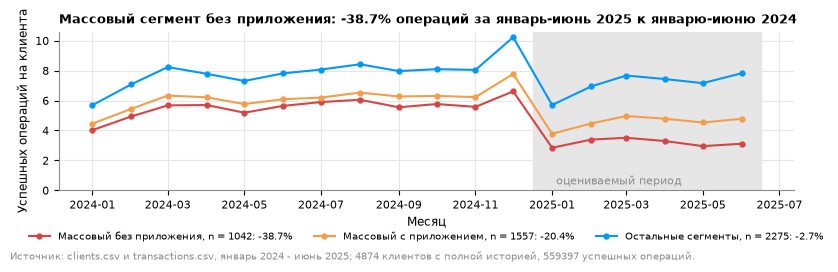

In [3]:
is_mass = metrics["segment"] == "Массовый"
metrics["line"] = np.where(~is_mass, "Остальные сегменты",
                           np.where(metrics["has_mobile_app"], "Массовый с приложением", "Массовый без приложения"))
ok["line"] = ok["client_id"].map(metrics["line"])
line_size = metrics["line"].value_counts()
per_client = ok.groupby(["month", "line"]).size().unstack() / line_size
change = yoy(ok, ["line"])

fig, ax = plt.subplots(figsize=(8.5, 2.4), layout="constrained")
for name, color in [("Массовый без приложения", RED), ("Массовый с приложением", ORANGE), ("Остальные сегменты", BLUE)]:
    ax.plot(per_client.index, per_client[name], marker="o", ms=3.5, color=color,
            label=f"{name}, n = {line_size[name]}: {pct(change[name])}")
ax.axvspan(EVAL_START - pd.Timedelta(days=15), per_client.index.max() + pd.Timedelta(days=15), color=GRAY_LIGHT, zorder=0)
ax.text(EVAL_START, 0.4, " оцениваемый период", color=GRAY, fontsize=8)
ax.set_ylim(0, None)
ax.set(xlabel="Месяц", ylabel="Успешных операций на клиента")
ax.set_title(f"Массовый сегмент без приложения: {pct(change['Массовый без приложения'])} операций "
             f"за январь-июнь 2025 к январю-июню 2024", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=3, fontsize=7.5)
add_source(fig, SOURCE)
plt.show()

У остальных сегментов 2025 год почти повторяет 2024 (-2.7% за январь-июнь к тому же периоду 2024 года): январский провал и весенний рост на прежнем уровне. В массовом сегменте активность упала в январе 2025 года и больше не вернулась. Разделение по приложению важно для кампании: с клиентами без приложения можно говорить только вне приложения.

### 4.2. Четверть клиентов потеряла больше половины активности, и это не шум

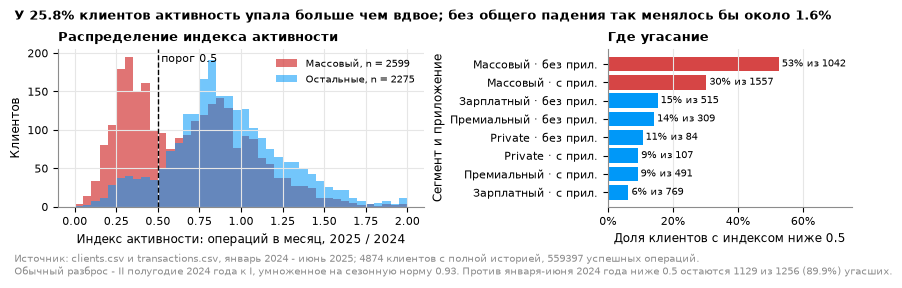

In [4]:
noise_low = (metrics["noise_index"] < FADE_THRESHOLD).mean()
fade_share = metrics["fade"].mean()
still_low = (metrics["fade"] & (metrics["index_yoy"] < FADE_THRESHOLD)).sum()

fig, axes = plt.subplots(1, 2, figsize=(8.5, 2.45), layout="constrained", width_ratios=[1.5, 1])
bins = np.arange(0, 2.05, 0.05)
axes[0].hist(metrics.loc[is_mass, "activity_index"].clip(upper=2), bins=bins, color=RED, alpha=0.75,
             label=f"Массовый, n = {is_mass.sum()}")
axes[0].hist(metrics.loc[~is_mass, "activity_index"].clip(upper=2), bins=bins, color=BLUE, alpha=0.55,
             label=f"Остальные, n = {(~is_mass).sum()}")
axes[0].axvline(FADE_THRESHOLD, color="black", ls="--", lw=1)
axes[0].text(FADE_THRESHOLD + 0.02, axes[0].get_ylim()[1] * 0.92, "порог 0.5", fontsize=8)
axes[0].set(xlabel="Индекс активности: операций в месяц, 2025 / 2024", ylabel="Клиентов")
axes[0].set_title("Распределение индекса активности", loc="left")
axes[0].legend(fontsize=7.5)

by = metrics.groupby(["segment", "has_mobile_app"], observed=True)["fade"].agg(["mean", "size"]).reset_index()
by["label"] = by["segment"].astype(str) + np.where(by["has_mobile_app"], " · с прил.", " · без прил.")
by = by.sort_values("mean")
axes[1].barh(by["label"], by["mean"], color=[RED if s == "Массовый" else BLUE for s in by["segment"]])
for y, (v, n) in enumerate(zip(by["mean"], by["size"])):
    axes[1].text(v, y, f" {v:.0%} из {n}", va="center", fontsize=7)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1))
axes[1].set_xlim(0, 0.75)
axes[1].set(xlabel="Доля клиентов с индексом ниже 0.5", ylabel="Сегмент и приложение")
axes[1].set_title("Где угасание", loc="left")
axes[1].grid(axis="y", visible=False)
fig.suptitle(f"У {fade_share:.1%} клиентов активность упала больше чем вдвое; без общего падения "
             f"так менялось бы около {noise_low:.1%}", x=0.01, ha="left", fontweight="bold", fontsize=9.5)
add_source(fig, SOURCE + f"\nОбычный разброс - II полугодие 2024 года к I, умноженное на сезонную норму 0.93. "
                f"Против января-июня 2024 года ниже 0.5 остаются {share(still_low, metrics['fade'].sum())} угасших.")
plt.show()

В массовом сегменте распределение двугорбое: одни клиенты живут как раньше (индекс около 0.9), другие на трети прежней активности. Порог 0.5 проходит по провалу между ними. В массовом сегменте без приложения угасла половина клиентов (53% из 1042), с приложением почти треть (30% из 1557), в остальных сегментах от 6% до 15%. 9 из 10 угасших (1129 из 1256) остаются ниже порога и при сравнении с теми же месяцами 2024 года, т.е. это не сезонность.

### 4.3. Развлечения - отдельная причина: клиенты без общего падения сократили только их

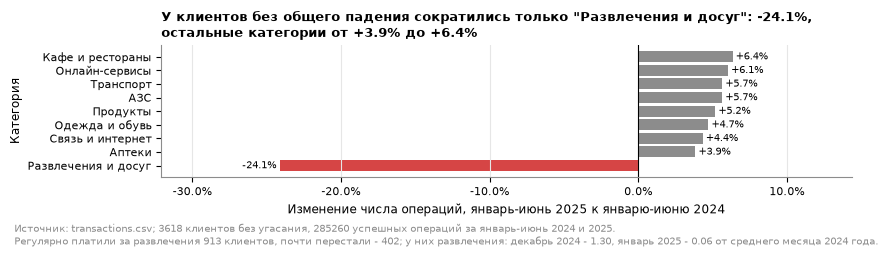

In [5]:
stable = ok[~ok["fade"]]
cat_change = yoy(stable, ["category"]).sort_values()
ent = cat_change.idxmin()

fig, ax = plt.subplots(figsize=(8.5, 2.15), layout="constrained")
ax.barh(cat_change.index.astype(str), cat_change.values,
        color=[RED if c == ent else GRAY for c in cat_change.index])
for y, v in enumerate(cat_change.values):
    ax.text(v, y, f" {pct(v)}" if v > 0 else f"{pct(v)} ", va="center", ha="left" if v > 0 else "right", fontsize=7.5)
ax.axvline(0, color="black", lw=0.8)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set_xlim(cat_change.min() - 0.08, cat_change.max() + 0.08)
ax.set(xlabel="Изменение числа операций, январь-июнь 2025 к январю-июню 2024", ylabel="Категория")
ax.set_title(f"У клиентов без общего падения сократились только \"{ent}\": {pct(cat_change[ent])},\n"
             f"остальные категории от {pct(cat_change.drop(ent).min())} до {pct(cat_change.max())}", loc="left")
ax.grid(axis="y", visible=False)
n_regular = (metrics["ent_base"] >= 12).sum()
g4_rule = metrics[metrics["group"].fillna("") == "G4_ушли_из_развлечений"]
g4_ent = (clean[clean["client_id"].isin(g4_rule.index) & (clean["status"] == "успешно")
                & (clean["category"] == "Развлечения и досуг")].groupby(["client_id", "month"]).size()
          .unstack(fill_value=0).reindex(g4_rule.index, fill_value=0))
g4_ent = g4_ent.div(g4_rule["ent_base"] / 12, axis=0).mean()
dec, jan = g4_ent[pd.Timestamp("2024-12-01")], g4_ent[pd.Timestamp("2025-01-01")]
add_source(fig, f"Источник: transactions.csv; {stable['client_id'].nunique()} клиентов без угасания, "
                f"{len(stable[stable['half'] != 'H2_2024'])} успешных операций за январь-июнь 2024 и 2025.\n"
                f"Регулярно платили за развлечения {n_regular} клиентов, почти перестали - {metrics['ent_lost'].sum()}; "
                f"у них развлечения: декабрь 2024 - {dec:.2f}, январь 2025 - {jan:.2f} от среднего месяца 2024 года.")
plt.show()

Это не равномерное снижение у всех. Из 913 клиентов, которые регулярно платили картой за развлечения, 402 почти перестали это делать, а остальные категории у клиентов без общего падения даже выросли на 3.9-6.4%. Обрыв приходится ровно на границу года (подпись под графиком), поэтому похоже на смену условий с 1 января 2025 года: закончилась акция, кешбэк или партнёрская программа в этой категории. В данных этого нет, гипотезу стоит проверить у продуктовой команды.

### 4.4. Оплаты переходят с пластика на токен, а провал онлайн-банка был временным

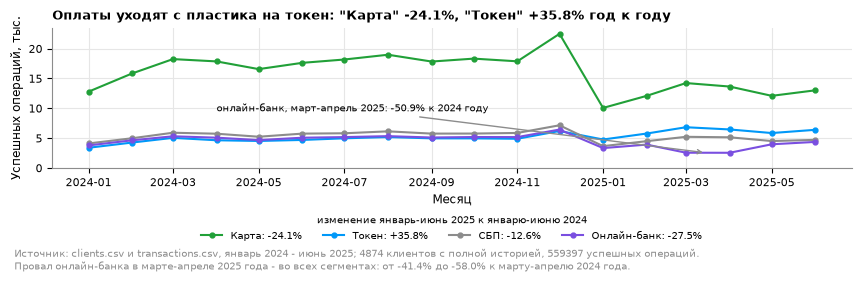

In [6]:
by_channel = ok.groupby(["month", "channel"], observed=True).size().unstack()
ch_change = yoy(ok, ["channel"])
online = by_channel["Онлайн-банк"]
dip = online["2025-03-01":"2025-04-01"].sum() / online["2024-03-01":"2024-04-01"].sum() - 1

ob = ok[ok["channel"] == "Онлайн-банк"]


def march_april(year):
    window = (ob["txn_datetime"] >= f"{year}-03-01") & (ob["txn_datetime"] < f"{year}-05-01")
    return ob[window]["client_id"].map(metrics["segment"]).value_counts()


ob_by_segment = march_april(2025) / march_april(2024) - 1

fig, ax = plt.subplots(figsize=(8.5, 2.4), layout="constrained")
for ch, color in [("Карта", GREEN), ("Токен", BLUE), ("СБП", GRAY), ("Онлайн-банк", PURPLE)]:
    ax.plot(by_channel.index, by_channel[ch] / 1000, marker="o", ms=3.5, color=color,
            label=f"{ch}: {pct(ch_change[ch])}")
ax.annotate(f"онлайн-банк, март-апрель 2025: {pct(dip)} к 2024 году",
            xy=(pd.Timestamp("2025-03-15"), online["2025-03-01":"2025-04-01"].mean() / 1000),
            xytext=(pd.Timestamp("2024-04-01"), 9.5), textcoords="data", fontsize=7.5, ha="left",
            arrowprops={"arrowstyle": "->", "color": GRAY})
ax.set_ylim(0, None)
ax.set(xlabel="Месяц", ylabel="Успешных операций, тыс.")
ax.set_title(f"Оплаты уходят с пластика на токен: \"Карта\" {pct(ch_change['Карта'])}, "
             f"\"Токен\" {pct(ch_change['Токен'])} год к году", loc="left")
ax.legend(fontsize=7.5, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.27),
          title="изменение январь-июнь 2025 к январю-июню 2024", title_fontsize=7.5)
add_source(fig, SOURCE + f"\nПровал онлайн-банка в марте-апреле 2025 года - во всех сегментах: "
                f"от {pct(ob_by_segment.max())} до {pct(ob_by_segment.min())} к марту-апрелю 2024 года.")
plt.show()

Рост токена при падении "Карты" это смена способа оплаты, а не отказ от карты, поэтому метрика считает все каналы вместе. В марте-апреле 2025 года операции онлайн-банка просели вдвое во всех сегментах сразу и в мае вернулись. Что именно случилось, сбой канала или неполная выгрузка, по данным не установить, но это не поведение отдельных клиентов. Здесь нужна не кампания, а разбор с теми, кто отвечает за канал и выгрузку.

## 5. Группы для кампании

Правило каждой группы: кто это и что с ними произошло. Угасание это индекс активности ниже 0.5, т.е. в январе-июне 2025 года операций в месяц меньше половины от 2024 года. Клиент, подходящий под несколько правил, попадает в первую группу по порядку G1 → G4: потеря всей активности важнее потери одной категории. В кампании только клиенты с согласием на коммуникацию. В таблице изменение операций в месяц за январь-июнь 2025 года к 2024 году внутри группы.

In [7]:
RULES = {
    "G1_массовый_без_приложения": ("Массовый сегмент, нет приложения", "угасание"),
    "G2_массовый_с_приложением": ("Массовый сегмент, есть приложение", "угасание"),
    "G3_зарплатный_премиальный_private": ("", "угасание"),
    "G4_ушли_из_развлечений": ("12+ операций в развлечениях в 2024 году", "развлечений меньше четверти от 2024 года"),
}
ENT = "Развлечения и досуг"
in_campaign = metrics[metrics["in_campaign"]].copy()
may_jun = ok[ok["txn_datetime"] >= pd.Timestamp("2025-05-01")].groupby("client_id").size()
in_campaign["zero_may_jun"] = ~in_campaign.index.isin(may_jun.index)
g3_mix = in_campaign.loc[in_campaign["group"] == "G3_зарплатный_премиальный_private", "segment"].value_counts()
RULES["G3_зарплатный_премиальный_private"] = (
    ", ".join(f"{k} ({v})" for k, v in g3_mix[g3_mix > 0].items()), "угасание")

camp_ops = ok[ok["client_id"].isin(in_campaign.index)].copy()


def change_by(by):
    """Изменение операций в месяц внутри группы: январь-июнь 2025 к 2024 году."""
    per_month = camp_ops.groupby(["group", by, "period"], observed=True).size().unstack("period")
    return ((per_month["eval"] / 6) / (per_month["base"] / 12) - 1).unstack(by)


def span(row):
    return f"{row.min() * 100:.0f}…{row.max() * 100:.0f}"


by_cat, by_chan = change_by("category"), change_by("channel")
groups = in_campaign.groupby("group").agg(клиентов=("activity_index", "size"),
                                          индекс=("activity_index", "median"),
                                          ноль=("zero_may_jun", "mean")).reset_index()
groups.insert(1, "кто", groups["group"].map(lambda g: RULES[g][0]))
groups.insert(2, "что произошло", groups["group"].map(lambda g: RULES[g][1]))
groups["развлечения, %"] = groups["group"].map(by_cat[ENT] * 100)
groups["прочие категории, %"] = groups["group"].map(by_cat.drop(columns=ENT).apply(span, axis=1))
groups["каналы, %"] = groups["group"].map(by_chan.apply(span, axis=1))
groups["group"] = groups["group"].map(GROUP_NAMES).str[:2]
groups = groups[["group", "кто", "что произошло", "клиентов", "индекс", "развлечения, %", "прочие категории, %",
                 "каналы, %", "ноль"]].rename(columns={"group": "группа", "индекс": "индекс активности",
                                                      "ноль": "нет операций в мае-июне"})
total = pd.DataFrame([{"группа": "Итого", "кто": "", "что произошло": "", "клиентов": len(in_campaign)}])
table(pd.concat([groups, total]), {"индекс активности": "{:.2f}",
                                  "развлечения, %": "{:.0f}",
                                  "нет операций в мае-июне": "{:.0%}"})

группа,кто,что произошло,клиентов,индекс активности,"развлечения, %","прочие категории, %","каналы, %",нет операций в мае-июне
G1,"Массовый сегмент, нет приложения",угасание,478,0.31,-72,-70…-66,-73…-66,22%
G2,"Массовый сегмент, есть приложение",угасание,423,0.33,-71,-69…-63,-72…-63,12%
G3,"Зарплатный (113), Премиальный (79), Private (18)",угасание,210,0.33,-70,-67…-61,-71…-61,14%
G4,12+ операций в развлечениях в 2024 году,развлечений меньше четверти от 2024 года,290,0.72,-91,-11…-6,-38…-24,0%
Итого,,,1401,-,-,-,-,-


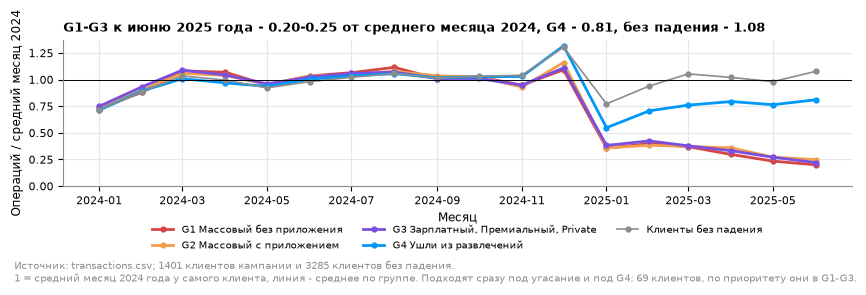

In [8]:
camp_ok = ok[ok["client_id"].isin(in_campaign.index) | ok["group"].isna()].copy()
camp_ok["who"] = camp_ok["group"].map(GROUP_NAMES).fillna("Клиенты без падения")
client_month = camp_ok.groupby(["client_id", "month"]).size().unstack(fill_value=0)
who = camp_ok.groupby("client_id")["who"].first()
relative = client_month.div(metrics.loc[client_month.index, "opm_base"], axis=0)
trajectory = relative.groupby(who).mean().T

fig, ax = plt.subplots(figsize=(8.5, 2.4), layout="constrained")
for name, color in zip(list(GROUP_NAMES.values()) + ["Клиенты без падения"], [RED, ORANGE, PURPLE, BLUE, GRAY]):
    ax.plot(trajectory.index, trajectory[name], marker="o", ms=3.5, color=color, lw=2 if name[0] == "G" else 1.2,
            label=name)
ax.axhline(1, color="black", lw=0.7)
ax.set_ylim(0, None)
ax.set(xlabel="Месяц", ylabel="Операций / средний месяц 2024")
last = trajectory.iloc[-1]
ax.set_title(f"G1-G3 к июню 2025 года - {last.iloc[:3].min():.2f}-{last.iloc[:3].max():.2f} от среднего месяца 2024, "
             f"G4 - {last.iloc[3]:.2f}, без падения - {last.iloc[4]:.2f}", loc="left")
ax.legend(fontsize=7.5, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
add_source(fig, f"Источник: transactions.csv; {len(in_campaign)} клиентов кампании и "
                f"{(metrics['group'].isna()).sum()} клиентов без падения.\n"
                "1 = средний месяц 2024 года у самого клиента, линия - среднее по группе. "
                f"Подходят сразу под угасание и под G4: {(metrics['n_rules'] > 1).sum()} клиентов, по приоритету они в G1-G3.")
plt.show()

- G1, Массовый без приложения, 478 клиентов. С января 2025 года у них треть прежней активности, к июню пятая часть, во всех категориях и каналах сразу, у 22% из 478 в мае-июне уже нет ни одной операции. Предложение: вернуть карту в ежедневные траты, связь через SMS, звонок, отделение и приглашение в приложение
- G2, Массовый с приложением, 423 клиента. Та же картина, и токен падает вместе с остальными каналами, т.е. это не переход на оплату телефоном. Предложение то же, связь через приложение
- G3, Зарплатный, Премиальный и Private, 210 клиентов. Сегменты объединены: по отдельности ни один не набирает 150 человек, а падение у них одинаковое. Сами эти сегменты в целом почти не падают (-2.7%, раздел 4.1), поэтому это отдельные клиенты, а не тренд, им нужна персональная коммуникация, а не рассылка
- G4, ушли из развлечений, 290 клиентов. Развлечения почти исчезли с января, остальные траты на уровне сезонной нормы. Предложение: кешбэк или партнёрская программа именно в этой категории

Причины пересекаются: 69 угасающих клиентов к тому же бросили развлечения, по приоритету они остались в G1-G3. Причины угасания в G1-G3 это гипотезы: данные показывают, как упала активность, но не почему.

## 6. Кого не включаем и почему

In [9]:
WHY = {
    "карта открыта в 2024-2025: база 2024 года не видна": "падение не измерить: операции видны только с открытия карты",
    "меньше 12 успешных операций в 2024 году": "индекс неустойчив: одна операция меняет его на десятки процентов",
    "подходят под группу, но нет согласия на коммуникацию": "связаться нельзя по условиям задачи",
    "подходят под группу, но у профиля две версии": "неизвестно, к какому сегменту применить правило",
    "перешли с пластиковой карты на токен":
        f"активность сохранилась: медиана индекса "
        f"{metrics.loc[metrics['token_switch'], 'activity_index'].median():.2f}",
    "умеренное снижение: индекс от 0.5 до 0.8":
        f"у всех клиентов расчёта такое снижение у "
        f"{metrics['activity_index'].between(FADE_THRESHOLD, MODERATE_UPPER, inclusive='left').sum()}, "
        f"из-за одного разброса и сезонности ожидалось бы около "
        f"{metrics['noise_index'].between(FADE_THRESHOLD, MODERATE_UPPER, inclusive='left').sum()}",
    "активность не упала: индекс 0.8 и выше": "кампания по возврату активности не нужна",
}
counts = clients["reason"].value_counts(sort=False)
counts.index = counts.index.astype(str).str.replace("\u2013", "-")
assert set(counts.index) == set(WHY) | {"в кампании"}
excluded = pd.DataFrame({"Кто": counts.index.astype(str), "Клиентов": counts.values})
excluded = excluded[excluded["Кто"] != "в кампании"].reset_index(drop=True)
excluded["Почему не берём"] = excluded["Кто"].map(WHY)
excluded.loc[len(excluded)] = ["Итого из справочника", excluded["Клиентов"].sum(), f"в кампании - {counts['в кампании']}"]
excluded.loc[len(excluded)] = ["Ушедшие: в справочнике действующих нет",
                               clean.loc[~clean["in_directory"], "client_id"].nunique(),
                               "уже не клиенты: это отток, а не снижение активности"]
table(excluded)

Кто,Клиентов,Почему не берём
карта открыта в 2024-2025: база 2024 года не видна,779,падение не измерить: операции видны только с открытия карты
меньше 12 успешных операций в 2024 году,5,индекс неустойчив: одна операция меняет его на десятки процентов
"подходят под группу, но нет согласия на коммуникацию",186,связаться нельзя по условиям задачи
"подходят под группу, но у профиля две версии",2,"неизвестно, к какому сегменту применить правило"
перешли с пластиковой карты на токен,394,активность сохранилась: медиана индекса 0.91
умеренное снижение: индекс от 0.5 до 0.8,823,"у всех клиентов расчёта такое снижение у 1197, из-за одного разброса и сезонности ожидалось бы около 1165"
активность не упала: индекс 0.8 и выше,2068,кампания по возврату активности не нужна
Итого из справочника,4257,в кампании - 1401
Ушедшие: в справочнике действующих нет,342,"уже не клиенты: это отток, а не снижение активности"


У каждого из 5658 клиентов справочника одна причина, первая подходящая по порядку таблицы, поэтому строки не пересекаются: 4257 исключённых вместе с 1401 клиентом кампании дают весь справочник. Лимит в 2000 клиентов это потолок, а не план. Добрать бюджет умеренным снижением можно, но такое снижение почти целиком объясняется сезонностью и обычным разбросом (строка таблицы), т.е. деньги ушли бы клиентам, у которых ничего не случилось.

## 7. Что проверили и что не подтвердилось

In [10]:
def fade_share(mask):
    return share(metrics.loc[mask, "fade"].sum(), mask.sum())


nn = metrics["city"] == "Нижний Новгород"
source = metrics["income_source"]
declined = {p: share((g["status"] == "отклонено").sum(), len(g)) for p, g in clean[clean["in_directory"]].groupby("period")}
expected = metrics.groupby(["segment", "has_mobile_app"], observed=True)["fade"].transform("mean")
by_branch = pd.DataFrame({"n": 1, "fade": metrics["fade"].astype(int), "exp": expected}).groupby(
    clients.set_index("client_id").loc[metrics.index, "branch_code"]).sum()
by_branch = by_branch[by_branch["n"] >= 8]
z = (by_branch["fade"] - by_branch["exp"]) / np.sqrt(by_branch["exp"] * (1 - by_branch["exp"] / by_branch["n"]))
score = metrics["satisfaction_score"]
other_scores = [(score == s).fillna(False).to_numpy(dtype=bool) for s in range(2, 6)]
other_rates = [metrics.loc[s, "fade"].mean() for s in other_scores]
hyp = pd.DataFrame([
    ("Нижний Новгород теряет клиентов из-за города",
     f"угасание внутри Массового: {fade_share(is_mass & nn)} в НН, {fade_share(is_mass & ~nn)} в других городах",
     "нет: город хуже из-за доли Массового сегмента"),
    ("Уходят клиенты с зарплатой в другом банке",
     f"угасание в Массовом: {fade_share(is_mass & (source == 'Зарплата в другом банке'))} при зарплате в другом банке, "
     f"{fade_share(is_mass & (source == 'Зарплата в нашем банке'))} - в нашем", "нет"),
    ("Выросли отказы по операциям",
     f"доля отклонённых: {declined['base']} в 2024 году, {declined['eval']} в январе-июне 2025", "нет"),
    ("Закрылись или плохо работают отдельные отделения",
     f"из {len(by_branch)} отделений с 8+ клиентами ни одно не отклоняется от ожидаемой доли угасания "
     f"больше чем на 3 ст. откл. (максимум {z.abs().max():.1f})", "нет"),
    ("Угасают недовольные обслуживанием",
     f"угасание при оценке 1: {fade_share((score == 1).fillna(False).to_numpy(dtype=bool))}, "
     f"при 2-5: {min(other_rates):.1%}-{max(other_rates):.1%}",
     f"как массовая причина нет: оценка есть у {share(score.notna().sum(), len(metrics))} клиентов"),
], columns=["Гипотеза", "Проверка", "Вывод"])
table(hyp)

Гипотеза,Проверка,Вывод
Нижний Новгород теряет клиентов из-за города,"угасание внутри Массового: 291 из 744 (39.1%) в НН, 729 из 1855 (39.3%) в других городах",нет: город хуже из-за доли Массового сегмента
Уходят клиенты с зарплатой в другом банке,"угасание в Массовом: 354 из 887 (39.9%) при зарплате в другом банке, 244 из 636 (38.4%) - в нашем",нет
Выросли отказы по операциям,"доля отклонённых: 8179 из 415966 (2.0%) в 2024 году, 3304 из 172437 (1.9%) в январе-июне 2025",нет
Закрылись или плохо работают отдельные отделения,из 194 отделений с 8+ клиентами ни одно не отклоняется от ожидаемой доли угасания больше чем на 3 ст. откл. (максимум 2.6),нет
Угасают недовольные обслуживанием,"угасание при оценке 1: 64 из 213 (30.0%), при 2-5: 21.5%-24.4%",как массовая причина нет: оценка есть у 1942 из 4874 (39.8%) клиентов


## 8. Приложение

### 8.1. Сводка журнала изменений

Полный журнал в `cleaning_log.csv`, одна строка на решение.

In [11]:
LOG_TYPE = {
    "полный дубль строки": "дубли",
    "у одного client_id две версии профиля": "дубли справочника",
    "одна операция записана дважды: с временем и без него": "дубли операций",
    "даты записаны текстом, у колонок разные форматы": "форматы: даты и \"Да/Нет\"",
    "дата записана текстом в двух форматах: с временем и без": "форматы: даты и \"Да/Нет\"",
    "\"Да\" и \"Нет\" записаны текстом": "форматы: даты и \"Да/Нет\"",
    "дата раньше начала выгрузки": "даты вне периода",
    "дата позже даты среза 30.06.2025": "даты вне периода",
    "разнобой написания": "разные написания",
    "категория не совпадает с MCC": "категория не совпадает с MCC",
    "код-заглушка -999 вместо дохода": "доход: заглушка и единицы",
    "доход записан в тысячах рублей": "доход: заглушка и единицы",
    "суммы в USD и EUR, курса в данных нет": "суммы: валюта и выбросы",
    "сумма за границей 1.5·IQR (лог-шкала, внутри категории)": "суммы: валюта и выбросы",
    "нет дохода": "пропуски", "нет месяца входа в приложение": "пропуски", "нет оценки": "пропуски",
    "клиента нет в справочнике действующих: ушёл из банка": "отбор для расчёта активности",
    "операция отклонена или это возврат": "отбор для расчёта активности",
    "карта открыта в 2024-2025 годах: база 2024 года видна не целиком": "отбор для расчёта активности",
    "меньше 12 успешных операций в 2024 году": "отбор для расчёта активности",
}
issue = (cleaning_log["issue"].str.replace("«", "\"").str.replace("»", "\"")
         .str.replace("\u2013", "-"))
log = cleaning_log.assign(тип=issue.map(LOG_TYPE))
is_dup = log["тип"] == "дубли"
log.loc[is_dup, "тип"] = np.where(log.loc[is_dup, "scope"].str.contains("transactions"), "дубли операций", "дубли справочника")
assert log["тип"].notna().all()
summary = log.groupby("тип", sort=False).agg(
    поля=("field", lambda s: ", ".join(dict.fromkeys(", ".join(s).split(", ")))),
    строк=("n_rows", lambda s: " + ".join(str(v) for v in s)),
    что_сделано=("action", lambda s: ", ".join(dict.fromkeys(a.split()[0].strip(":,") for a in s))),
).reset_index()
assert 5 <= len(summary) <= 10
table(summary.rename(columns={"что_сделано": "что сделано"})).set_caption(
    f"Решений в журнале: {len(cleaning_log)}, ниже они сведены к {len(summary)} типам")

тип,поля,строк,что сделано
дубли справочника,"все поля, city, segment",42 + 13,удалено
дубли операций,"все поля, txn_datetime",1266 + 234,удалено
"форматы: даты и ""Да/Нет""","birth_date, registration_date, card_open_date, app_last_login, txn_datetime, has_mobile_app, marketing_opt_in",5658 + 617989 + 5658,преобразовано
даты вне периода,txn_datetime,2 + 79,удалено
доход: заглушка и единицы,monthly_income,44 + 124,"заменено, исправлено"
суммы: валюта и выбросы,"amount, currency",2534 + 4287,оставлено
разные написания,"city, category",1634 + 51162,нормализация
категория не совпадает с MCC,mcc_code,1706,оставлено
пропуски,"monthly_income, app_last_login, satisfaction_score",569 + 2224 + 3383,оставлено
отбор для расчёта активности,"client_id, status, card_open_date",29505 + 18549 + 779 + 5,исключено


### 8.2. Методика

- Очистка: удалены полные дубли (42 строки справочника и 1266 операций) и вторые записи одной операции без времени (234), удалена 81 операция вне периода с 2024-01-01 по 2025-06-30. Даты разобраны явными форматами, написания города и категории сведены к одному. Доход: `-999` заменён на пропуск, значения меньше 1000 умножены на 1000
- Клиенты расчёта: карта открыта до 2024-01-01 (операции в данных начинаются с даты открытия текущей карты) и не меньше 12 успешных операций в 2024 году, всего 4874 клиента
- Метрика: `opm_base` = успешных операций за 2024 год / 12, `opm_eval` = успешных операций за январь-июнь 2025 / 6, индекс активности = `opm_eval / opm_base`. Учитываются все каналы и валюты
- Угасание: индекс < 0.5. Проверка на шум: отношение II полугодия 2024 года к I у тех же клиентов, нормированное на его медиану и умноженное на сезонную норму 0.93, так выглядел бы индекс без общего падения, ниже 0.5 он у 1.6% клиентов. Проверка на сезонность: 1129 из 1256 угасших остаются ниже 0.5 и против января-июня 2024 года
- G4: не меньше 12 операций в "Развлечениях и досуге" в 2024 году и индекс развлечений < 0.25
- Приоритет групп: G1 → G2 → G3 → G4. Отбор: согласие на маркетинг и одна версия профиля
- Перешедшие на токен: вне групп, операций "Картой" в месяц меньше половины от 2024 года, доля токена в операциях выросла не меньше чем на 20 процентных пунктов
- "Год к году": январь-июнь 2025 к январю-июню 2024 по числу успешных операций, без влияния сезонности
- Устойчивость: размеры G1-G3 в кампании при другом пороге и без онлайн-банка, у которого в марте-апреле 2025 года провал во всех сегментах

In [12]:
ok_c = metrics["marketing_opt_in"] & ~metrics["profile_conflict"]


def fade_groups(fade):
    return {"G1": (is_mass & ~metrics["has_mobile_app"] & fade & ok_c).sum(),
            "G2": (is_mass & metrics["has_mobile_app"] & fade & ok_c).sum(),
            "G3": (~is_mass & fade & ok_c).sum()}


sens = pd.DataFrame({f"порог {t}": fade_groups(metrics["activity_index"] < t) for t in [0.4, 0.5, 0.6]})
sens["порог 0.5 без онлайн-банка"] = pd.Series(fade_groups(metrics["index_no_online"] < FADE_THRESHOLD))
table(sens.rename_axis("группа").reset_index())

группа,порог 0.4,порог 0.5,порог 0.6,порог 0.5 без онлайн-банка
G1,373,478,535,459
G2,302,423,505,409
G3,143,210,309,204


### 8.3. Использование ИИ

ИИ-ассистент Claude использовался для консультации по принимаемым решениям и для ревью кода ноутбуков. 